# Latent-action model (LAM), T1

Name the motion between two frames with a few numbers, from video alone. Script version: `experiments/lam/scripts/lam.py` (results in `experiments/lam/notes.md`).


In [13]:
%load_ext autoreload
%autoreload 2
from notebook_cache import NotebookCache

cache = NotebookCache('../cache/lam_nb')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Step 0: data

Joints, demo ids, top-camera frames (decoded once by the script, `cache/lam/`).


In [14]:
import numpy as np
from frozendict import frozendict
from uwm_parts import load_table

NAME = 'pick_place_cube_n100'
state, action, episode = load_table(NAME)
top = np.load(f'../cache/lam/{NAME}_top.npy')  # [N, 3, 128, 128] uint8
print(f'{top.shape=}  {state.shape=}  demos {episode.max() + 1}')

top.shape=(21295, 3, 128, 128)  state.shape=(21295, 8)  demos 100


## Step 1: what changes in 8 steps

Three moments of one demo: frame t, frame t+8, and where they differ.


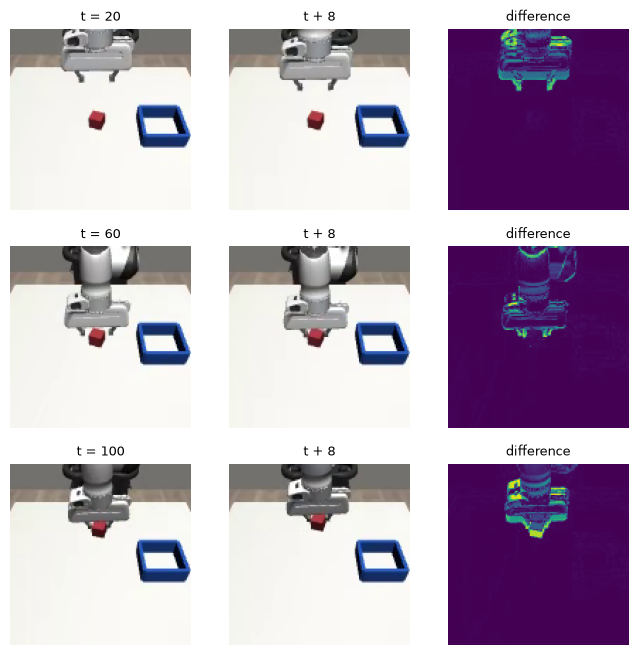

In [15]:
import matplotlib.pyplot as plt

GAP = 8
start = np.flatnonzero(episode == 31)[0]
fig, axs = plt.subplots(3, 3, figsize=(8, 8))
for row, step in enumerate([20, 60, 100]):
    f0, f1 = top[start + step], top[start + step + GAP]
    diff = np.abs(f1.astype(int) - f0.astype(int)).sum(0)  # [128, 128]
    for ax, im, name in zip(
        axs[row],
        [f0.transpose(1, 2, 0), f1.transpose(1, 2, 0), diff],
        [f't = {step}', f't + {GAP}', 'difference'],
    ):
        ax.imshow(im)
        ax.set_title(name, fontsize=9)
        ax.axis('off')
plt.show()

In [16]:
ok = np.flatnonzero(episode[:-GAP] == episode[GAP:])  # rows t with t + 8 in the same demo
d = np.abs(top[ok[::50] + GAP].astype(int) - top[ok[::50]].astype(int)).sum(1)  # [n, 128, 128]
print(f'{len(d)} pairs: {(d > 30).mean():.1%} of pixels change in 8 steps')

410 pairs: 10.2% of pixels change in 8 steps


## Step 2: the encoder

(frame t, frame t+8) stacked as 6 channels -> 3 stride-2 convs -> average over the map -> z (8 numbers).


In [17]:
import torch
from torch import nn

dev = 'cuda'
Z = 8  # numbers in a motion note


def down(i, o):
    # halves height and width
    return nn.Sequential(nn.Conv2d(i, o, 4, stride=2, padding=1), nn.GroupNorm(8, o), nn.SiLU())


torch.manual_seed(0)
enc = nn.ModuleDict(
    dict(
        convs=nn.Sequential(
            down(6, 32), down(32, 64), down(64, 128), nn.Conv2d(128, 128, 3, padding=1)
        ),
        out=nn.Linear(128, Z),  # after averaging over the map
    )
).to(dev)

In [18]:
x = torch.tensor(np.concatenate([top[ok[:3]], top[ok[:3] + GAP]], 1), device=dev) / 255
with torch.no_grad():
    h = enc['convs'](x)
    z = enc['out'](h.mean((2, 3)))
print(f'{x.shape=}  {h.shape=}  {z.shape=}')

x.shape=torch.Size([3, 6, 128, 128])  h.shape=torch.Size([3, 128, 16, 16])  z.shape=torch.Size([3, 8])


## Step 3: the decoder

(frame t, z) -> frame t+8. Frame t becomes a 16x16 map; z scales and shifts every cell of it (FiLM); 3 up-convs draw the change, added to frame t.


In [19]:
def up(i, o):
    # doubles height and width
    return nn.Sequential(
        nn.ConvTranspose2d(i, o, 4, stride=2, padding=1), nn.GroupNorm(8, o), nn.SiLU()
    )


dec = nn.ModuleDict(
    dict(
        convs=nn.Sequential(
            down(3, 32), down(32, 64), down(64, 128), nn.Conv2d(128, 128, 3, padding=1)
        ),
        film=nn.Linear(Z, 2 * 128),  # z -> a scale and a shift per feature
        up=nn.Sequential(
            up(128, 64), up(64, 32), nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1)
        ),
    )
).to(dev)
print(f'{sum(p.numel() for m in (enc, dec) for p in m.parameters()) / 1e6:.2f}M params')

0.80M params


In [20]:
f0 = x[:, :3]  # frame t of the 3 pairs
with torch.no_grad():
    scale, shift = dec['film'](z)[..., None, None].chunk(2, 1)  # [3, 128, 1, 1] each
    g = dec['convs'](f0) * (1 + scale) + shift  # [3, 128, 16, 16]
    f1_hat = f0 + dec['up'](g)
print(f'{g.shape=}  {f1_hat.shape=}')

g.shape=torch.Size([3, 128, 16, 16])  f1_hat.shape=torch.Size([3, 3, 128, 128])


## Step 4: the loss

Redraw frame t+8; squared pixel error, against copying frame t ("nothing moved").


In [21]:
val = np.random.default_rng(0).permutation(100)[:10]  # the dreamzero split's held-out demos
rows = frozendict(train=ok[~np.isin(episode[ok], val)], val=ok[np.isin(episode[ok], val)])
print({k: len(v) for k, v in rows.items()})

{'train': 18436, 'val': 2059}


In [24]:
def frames(r):
    # rows -> [B, 3, 128, 128] float in [0, 1] on the GPU
    return torch.tensor(top[r], device=dev) / 255


def note(f0, f1):
    # the encoder: a pair of frames -> z [B, Z]
    return enc['out'](enc['convs'](torch.cat([f0, f1], 1)).mean((2, 3)))


def redraw(f0, z):
    # the decoder: frame t + z -> guess of frame t+8 [B, 3, 128, 128]
    scale, shift = dec['film'](z)[..., None, None].chunk(2, 1)
    return f0 + dec['up'](dec['convs'](f0) * (1 + scale) + shift)

In [28]:
r = np.random.default_rng(0).choice(rows['train'], 64)
f0, f1 = frames(r), frames(r + GAP)
with torch.no_grad():
    err = (redraw(f0, note(f0, f1)) - f1).square().mean()
print(f'untrained: draw {err:.4f}   copy frame t {(f0 - f1).square().mean():.4f}')

untrained: draw 0.3521   copy frame t 0.0126


## Step 5: pack into a class

Steps 2-4's pieces as one `LAM` module; same weights must give the same z and guess.

In [29]:
class LAM(nn.Module):
    # step 2's encoder + step 3's decoder; note and redraw as in step 4
    def __init__(self):
        super().__init__()
        self.enc_convs = nn.Sequential(
            down(6, 32), down(32, 64), down(64, 128), nn.Conv2d(128, 128, 3, padding=1)
        )
        self.enc_out = nn.Linear(128, Z)
        self.dec_convs = nn.Sequential(
            down(3, 32), down(32, 64), down(64, 128), nn.Conv2d(128, 128, 3, padding=1)
        )
        self.film = nn.Linear(Z, 2 * 128)
        self.up = nn.Sequential(
            up(128, 64), up(64, 32), nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1)
        )

    def note(self, f0, f1):
        return self.enc_out(self.enc_convs(torch.cat([f0, f1], 1)).mean((2, 3)))

    def redraw(self, f0, z):
        scale, shift = self.film(z)[..., None, None].chunk(2, 1)
        return f0 + self.up(self.dec_convs(f0) * (1 + scale) + shift)

In [30]:
net = LAM().to(dev)
loose = [enc['convs'], enc['out'], dec['convs'], dec['film'], dec['up']]
for m, piece in zip([net.enc_convs, net.enc_out, net.dec_convs, net.film, net.up], loose):
    m.load_state_dict(piece.state_dict())
with torch.no_grad():
    z = net.note(f0, f1)
    diff = [
        (z - note(f0, f1)).abs().max().item(),
        (net.redraw(f0, z) - redraw(f0, z)).abs().max().item(),
    ]
print(f'max diff vs loose pieces (z, guess): {diff}')

max diff vs loose pieces (z, guess): [0.0, 4.76837158203125e-07]


## Step 6: train on forward pairs

Every 1000 steps, on 512 val pairs, the drawing error / copy's with: the right z, the average z (a blank note), another pair's z (a wrong note). If z is used, right < average < wrong.

In [32]:
@cache
def train_lam(reverse: bool, steps: int = 10000, B: int = 64, lr: float = 1e-3, seed: int = 0):
    # a fresh LAM; reverse: half the pairs played backwards;
    # out: weights (CPU), log rows [step, train loss, val right z, avg z, wrong z] (all / copy)
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = LAM().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    vr = np.random.default_rng(1).choice(rows['val'], 512, replace=False)
    v0, v1 = frames(vr), frames(vr + GAP)
    copy_err = (v0 - v1).square().mean()
    log = []
    for step in range(1, steps + 1):
        r0 = rng.choice(rows['train'], B)
        r1 = r0 + GAP
        if reverse:
            back = rng.random(B) < 0.5
            r0, r1 = np.where(back, r1, r0), np.where(back, r0, r1)
        f0, f1 = frames(r0), frames(r1)
        with torch.autocast('cuda', dtype=torch.bfloat16):
            loss = (net.redraw(f0, net.note(f0, f1)).float() - f1).square().mean()
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        opt.step()
        sched.step()
        if step % 1000 == 0:
            with torch.no_grad():
                z = net.note(v0, v1)
                err = [
                    (net.redraw(v0, x) - v1).square().mean() / copy_err
                    for x in (z, z.mean(0).expand_as(z), z.roll(1, 0))
                ]
            log.append([step, loss.item(), *[e.item() for e in err]])
            print(
                f'{step:5d}  train {loss:.5f}   val / copy: right z {err[0]:.3f}  '
                f'average z {err[1]:.3f}  wrong z {err[2]:.3f}'
            )
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train_lam: not cached, will compute


In [ ]:
run_fwd = train_lam(reverse=False)